In [3]:
import tensorflow as tf
from tensorflow import keras

base_path = "/app/data/processed/classification"
image_size = (299,299)
batch_size = 32


train_ds = keras.utils.image_dataset_from_directory(
    base_path + "/train",
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=True,
    seed=42
)


val_ds = keras.utils.image_dataset_from_directory(
    base_path + "/val",
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=False
)

test_ds = keras.utils.image_dataset_from_directory(
    base_path + "/test",
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=False
)

class_names = train_ds.class_names
print(class_names)

Found 5600 files belonging to 4 classes.
Found 1053 files belonging to 4 classes.
Found 1054 files belonging to 4 classes.
['glioma', 'meningioma', 'notumor', 'pituitary']


In [4]:
from tensorflow.keras.applications.inception_v3 import preprocess_input


train_ds = train_ds.map(lambda x ,y:(preprocess_input(x),y))
val_ds = val_ds.map(lambda x ,y:(preprocess_input(x),y))
test_ds = test_ds.map(lambda x ,y:(preprocess_input(x),y))

In [5]:
for images , labels in train_ds.take(1):
    print("images shape: ", images.shape)
    print("lables shape: ", labels.shape)
    print("min pixel : ", images.numpy().min())
    print("min pixel : ", images.numpy().max())


images shape:  (32, 299, 299, 3)
lables shape:  (32, 4)
min pixel :  -1.0
min pixel :  1.0


2026-10-23 10:20:35.668368: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [6]:
from tensorflow.keras.applications import InceptionV3

base_model = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(299,299,3)
)

base_model.trainable = False

In [ ]:
from tensorflow.keras import layers
from tensorflow import keras

model = keras.Sequential([
    keras.Input(shape=(299,299,3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(4,activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [10]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import os

os.makedirs("/app/models/classification", exist_ok=True)
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
checkpoint = ModelCheckpoint(
    "/app/models/classification/best_feature_extraction.keras",
    monitor="val_loss",
    save_best_only=True
)

In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop,checkpoint]
)

Epoch 1/20


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792833794.626370     736 service.cc:145] XLA service 0x7e3d6c004af0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792833794.630286     736 service.cc:153]   StreamExecutor device (0): NVIDIA RTX 2000 Ada Generation Laptop GPU, Compute Capability 8.9
2026-10-24 09:23:15.606320: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-24 09:23:19.131158: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


  1/175 ━━━━━━━━━━━━━━━━━━━━ 1:40:56 35s/step - accuracy: 0.2188 - loss: 1.5738

I0000 00:00:1792833820.687164     736 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1792833820.699707     736 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.7404 - loss: 0.6478

I0000 00:00:1792833850.147857    1562 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2455', 180 bytes spill stores, 180 bytes spill loads

I0000 00:00:1792833851.926604     733 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1792833856.140174    1605 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2455', 244 bytes spill stores, 244 bytes spill loads



175/175 ━━━━━━━━━━━━━━━━━━━━ 91s 321ms/step - accuracy: 0.7404 - loss: 0.6478 - val_accuracy: 0.8519 - val_loss: 0.4228
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 25s 144ms/step - accuracy: 0.8473 - loss: 0.4210 - val_accuracy: 0.8689 - val_loss: 0.3799
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 149ms/step - accuracy: 0.8664 - loss: 0.3662 - val_accuracy: 0.8822 - val_loss: 0.3403
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 24s 138ms/step - accuracy: 0.8830 - loss: 0.3262 - val_accuracy: 0.8908 - val_loss: 0.3100
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 147ms/step - accuracy: 0.8882 - loss: 0.3081 - val_accuracy: 0.8879 - val_loss: 0.3017
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 25s 140ms/step - accuracy: 0.8893 - loss: 0.2939 - val_accuracy: 0.8822 - val_loss: 0.2969
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 25s 140ms/step - accuracy: 0.8948 - loss: 0.2795 - val_accuracy: 0.8889 - val_loss: 0.2897
Epoch 8/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 23s 132ms/step - accuracy: 0.8968 - loss: 0.2707 - val

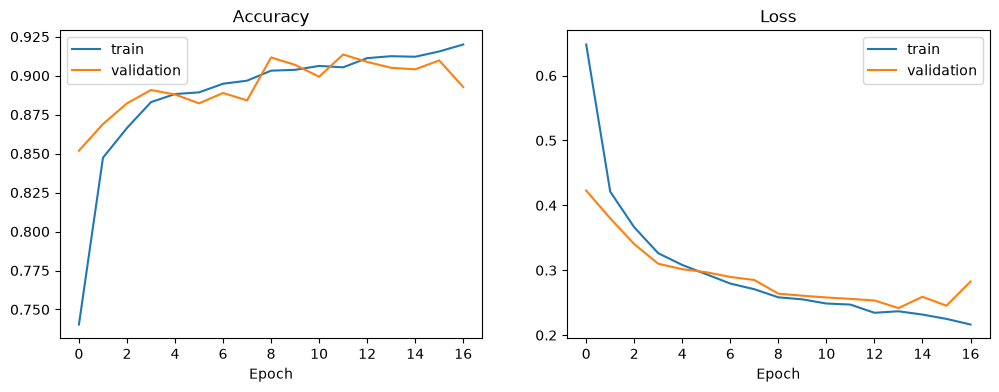

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.savefig("/app/reports/training_feature_extraction.png")
plt.show()

In [17]:
print("Epochs run:", len(history.history["val_loss"]))
print("Best val_loss:", min(history.history["val_loss"]))

Epochs run: 17
Best val_loss: 0.24173994362354279


In [18]:
import numpy as np

y_true = []
for images,labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(),axis=1))
    
y_pred = np.argmax(model.predict(test_ds),axis=1)

2026-10-24 13:47:42.026076: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
I0000 00:00:1792849672.308304     736 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads



32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step

I0000 00:00:1792849677.537432    3398 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2412', 244 bytes spill stores, 244 bytes spill loads



33/33 ━━━━━━━━━━━━━━━━━━━━ 30s 592ms/step


I0000 00:00:1792849691.532784     735 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads



In [19]:
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred,target_names=class_names))

              precision    recall  f1-score   support

      glioma       0.91      0.88      0.89       243
  meningioma       0.83      0.78      0.81       247
     notumor       0.96      0.98      0.97       300
   pituitary       0.90      0.96      0.93       264

    accuracy                           0.91      1054
   macro avg       0.90      0.90      0.90      1054
weighted avg       0.90      0.91      0.90      1054



In [20]:
train_loss, train_acc = model.evaluate(train_ds)
test_loss, test_acc = model.evaluate(test_ds)

print("train acc: ", train_acc)
print("test acc: ", test_acc)

175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step - accuracy: 0.9457 - loss: 0.1618
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.9051 - loss: 0.2479

I0000 00:00:1792850064.201685     735 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads



33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 137ms/step - accuracy: 0.9051 - loss: 0.2479
train acc:  0.9457142949104309
test acc:  0.9051233530044556


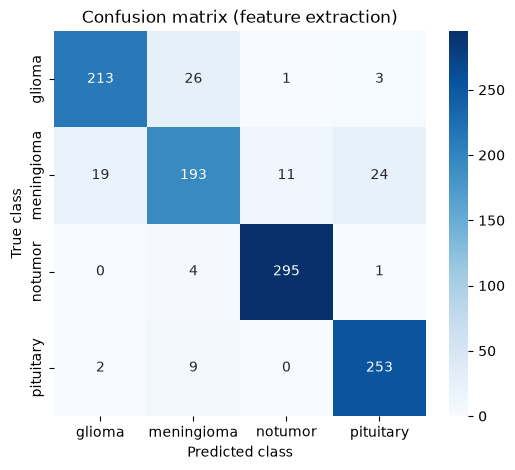

In [21]:
import seaborn as sns 
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix (feature extraction)")
plt.savefig("/app/reports/confusion_matrix_feature_extraction.png")
plt.show()

In [22]:
print(cm)

[[213  26   1   3]
 [ 19 193  11  24]
 [  0   4 295   1]
 [  2   9   0 253]]


In [26]:
print(len(base_model.layers))

311


In [23]:
fe_test_acc = test_acc
fe_y_pred = y_pred

base_model.trainable = True

for layer in base_model.layers[:50]:
    layer.trainable = False


for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,827,374 (83.26 MB)

 Trainable params: 21,248,516 (81.06 MB)

 Non-trainable params: 562,464 (2.15 MB)

 Optimizer params: 16,394 (64.04 KB)

In [24]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"])

In [ ]:
early_stop_ft = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True)

checkpoint_ft = ModelCheckpoint(
    "/app/models/classification/best_fine_tuning.keras",
    monitor="val_loss",
    save_best_only=True)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop_ft, checkpoint_ft])

Epoch 1/20


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


175/175 ━━━━━━━━━━━━━━━━━━━━ 99s 279ms/step - accuracy: 0.9248 - loss: 0.1900 - val_accuracy: 0.9468 - val_loss: 0.1402
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 39s 221ms/step - accuracy: 0.9768 - loss: 0.0635 - val_accuracy: 0.9639 - val_loss: 0.0971
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 39s 220ms/step - accuracy: 0.9936 - loss: 0.0233 - val_accuracy: 0.9706 - val_loss: 0.0962
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 35s 200ms/step - accuracy: 0.9937 - loss: 0.0171 - val_accuracy: 0.9677 - val_loss: 0.1028
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 37s 212ms/step - accuracy: 0.9959 - loss: 0.0120 - val_accuracy: 0.9630 - val_loss: 0.1313
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 35s 199ms/step - accuracy: 0.9971 - loss: 0.0091 - val_accuracy: 0.9658 - val_loss: 0.1136


In [27]:
trainable = [l for l in base_model.layers if l.trainable]
print("Total layers in base:", len(base_model.layers))
print("Trainable layers:", len(trainable))

Total layers in base: 311
Trainable layers: 182


In [28]:
y_pred_ft = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred_ft, target_names=class_names))

train_loss, train_acc_ft = model.evaluate(train_ds)
test_loss, test_acc_ft = model.evaluate(test_ds)
print("Train accuracy:", train_acc_ft)
print("Test accuracy:", test_acc_ft)

33/33 ━━━━━━━━━━━━━━━━━━━━ 17s 185ms/step
              precision    recall  f1-score   support

      glioma       1.00      0.93      0.96       243
  meningioma       0.92      0.94      0.93       247
     notumor       0.99      1.00      1.00       300
   pituitary       0.95      0.98      0.96       264

    accuracy                           0.96      1054
   macro avg       0.96      0.96      0.96      1054
weighted avg       0.96      0.96      0.96      1054

175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.9975 - loss: 0.0084
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 122ms/step - accuracy: 0.9630 - loss: 0.1176
Train accuracy: 0.9975000023841858
Test accuracy: 0.96299809217453


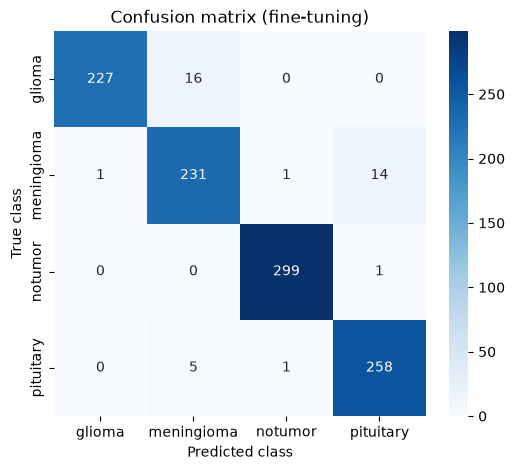

[[227  16   0   0]
 [  1 231   1  14]
 [  0   0 299   1]
 [  0   5   1 258]]


In [29]:
cm_ft = confusion_matrix(y_true, y_pred_ft)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_ft, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix (fine-tuning)")
plt.savefig("/app/reports/confusion_matrix_fine_tuning.png")
plt.show()

print(cm_ft)

In [30]:
print("Feature extraction test accuracy:", fe_test_acc)
print("Fine-tuning test accuracy:       ", test_acc_ft)

Feature extraction test accuracy: 0.9051233530044556
Fine-tuning test accuracy:        0.96299809217453


In [31]:
model.save("/app/models/classification/inceptionv3_final.keras")
print("Saved")

Saved
